In [5]:
import pandas as pd
import requests
import zipfile
import io
import os
from tqdm.auto import tqdm

BASE_URL = "https://data.gdeltproject.org/events/"

# Start with ONE month for testing
YEAR = 2019
MONTH = 1

os.makedirs("/kaggle/working/gdelt", exist_ok=True)

all_protests = []

for day in range(1, 32):
    date = f"{YEAR}{MONTH:02d}{day:02d}"
    url = f"{BASE_URL}{date}.export.CSV.zip"

    try:
        r = requests.get(url, timeout=60)

        if r.status_code != 200:
            continue

        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            filename = z.namelist()[0]

            df = pd.read_csv(
                z.open(filename),
                sep="\t",
                header=None,
                low_memory=False
            )

        # GDELT EventRootCode is column 28
        protests = df[df[28].astype(str) == "14"].copy()

        all_protests.append(protests)

        print(date, "→", len(protests), "protest events")

    except Exception as e:
        print(date, "→ skipped:", e)

if all_protests:
    gdelt_protests = pd.concat(all_protests, ignore_index=True)
    print("\nTotal protest events:", len(gdelt_protests))
else:
    gdelt_protests = pd.DataFrame()
    print("No data downloaded.")

20190101 → 715 protest events
20190102 → 1166 protest events
20190103 → 1309 protest events
20190104 → 1129 protest events
20190105 → 817 protest events
20190106 → 880 protest events
20190107 → 1360 protest events
20190108 → 1697 protest events
20190109 → 1575 protest events
20190110 → 1568 protest events
20190111 → 1722 protest events
20190112 → 1294 protest events
20190113 → 1063 protest events
20190114 → 1548 protest events
20190115 → 1626 protest events
20190116 → 1708 protest events
20190117 → 1567 protest events
20190118 → 1625 protest events
20190119 → 1357 protest events
20190120 → 1481 protest events
20190121 → 1692 protest events
20190122 → 1770 protest events
20190123 → 1883 protest events
20190124 → 2001 protest events
20190125 → 1696 protest events
20190126 → 1343 protest events
20190127 → 1097 protest events
20190128 → 1657 protest events
20190129 → 1585 protest events
20190130 → 1659 protest events
20190131 → 1811 protest events

Total protest events: 45401


In [6]:
print(gdelt_protests.shape)
gdelt_protests.head()

(45401, 58)


,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
0,813415784,20181202,201812,2018,2018.9096,OPP,PROTESTER,NaN,NaN,NaN,...,-2424066,4,"Davao City, Davao City, Philippines",RP,RPC3,7.07306,125.613,-2424066,20190101,https://www.theage.com.au/world/asia/philippin...
1,813415785,20181202,201812,2018,2018.9096,OPP,PROTESTER,NaN,NaN,NaN,...,-2437894,4,"Davao City, Davao City, Philippines",RP,RPC3,7.07306,125.613,-2424066,20190101,https://www.theage.com.au/world/asia/philippin...
2,813415786,20181202,201812,2018,2018.9096,OPP,PROTESTER,NaN,NaN,NaN,...,-2437894,4,"Manila, Manila, Philippines",RP,RPD9,14.60420,120.982,-2437894,20190101,https://www.theage.com.au/world/asia/philippin...
3,813415787,20181202,201812,2018,2018.9096,OPP,PROTESTER,NaN,NaN,NaN,...,-2437894,4,"Manila, Manila, Philippines",RP,RPD9,14.60420,120.982,-2437894,20190101,https://www.theage.com.au/world/asia/philippin...
4,813416311,20190101,201901,2019,2019.0027,CHRCTH,CATHOLIC BISHOP,NaN,NaN,NaN,...,-2437894,4,"Manila, Manila, Philippines",RP,RPD9,14.60420,120.982,-2437894,20190101,https://www.theage.com.au/world/asia/philippin...


In [7]:
gdelt_protests.to_csv(
    "/kaggle/working/gdelt/gdelt_protests_2019_01.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [8]:
import pandas as pd
import requests
import zipfile
import io
import os

BASE_URL = "https://data.gdeltproject.org/events/"

YEAR = 2019
MONTH = 1

os.makedirs("/kaggle/working/gdelt", exist_ok=True)

all_protests = []

for day in range(1, 32):

    date = f"{YEAR}{MONTH:02d}{day:02d}"
    url = f"{BASE_URL}{date}.export.CSV.zip"

    try:
        response = requests.get(url, timeout=60)

        if response.status_code != 200:
            continue

        with zipfile.ZipFile(io.BytesIO(response.content)) as z:

            filename = z.namelist()[0]

            df = pd.read_csv(
                z.open(filename),
                sep="\t",
                header=None,
                low_memory=False
            )

        # GDELT EventRootCode = column 28
        protests = df[df[28].astype(str) == "14"].copy()

        all_protests.append(protests)

        print(date, "→", len(protests), "protest events")

    except Exception as e:
        print(date, "→ skipped:", e)

if all_protests:

    gdelt_protests = pd.concat(
        all_protests,
        ignore_index=True
    )

    print("\nTotal protest events:", len(gdelt_protests))

else:

    gdelt_protests = pd.DataFrame()

    print("No data downloaded.")

20190101 → 715 protest events
20190102 → 1166 protest events
20190103 → 1309 protest events
20190104 → 1129 protest events
20190105 → 817 protest events
20190106 → 880 protest events
20190107 → 1360 protest events
20190108 → 1697 protest events
20190109 → 1575 protest events
20190110 → 1568 protest events
20190111 → 1722 protest events
20190112 → 1294 protest events
20190113 → 1063 protest events
20190114 → 1548 protest events
20190115 → 1626 protest events
20190116 → 1708 protest events
20190117 → 1567 protest events
20190118 → 1625 protest events
20190119 → 1357 protest events
20190120 → 1481 protest events
20190121 → 1692 protest events
20190122 → 1770 protest events
20190123 → 1883 protest events
20190124 → 2001 protest events
20190125 → 1696 protest events
20190126 → 1343 protest events
20190127 → 1097 protest events
20190128 → 1657 protest events
20190129 → 1585 protest events
20190130 → 1659 protest events
20190131 → 1811 protest events

Total protest events: 45401


In [10]:
# Show the GDELT column numbers and names
for i, col in enumerate(gdelt_protests.columns):
    print(i, col)

0 0
1 1
2 2
3 3
4 4
5 5
6 6
7 7
8 8
9 9
10 10
11 11
12 12
13 13
14 14
15 15
16 16
17 17
18 18
19 19
20 20
21 21
22 22
23 23
24 24
25 25
26 26
27 27
28 28
29 29
30 30
31 31
32 32
33 33
34 34
35 35
36 36
37 37
38 38
39 39
40 40
41 41
42 42
43 43
44 44
45 45
46 46
47 47
48 48
49 49
50 50
51 51
52 52
53 53
54 54
55 55
56 56
57 57


In [11]:
display(gdelt_protests.head(3).T)

,0,1,2
0,813415784,813415785,813415786
1,20181202,20181202,20181202
2,201812,201812,201812
3,2018,2018,2018
4,2018.9096,2018.9096,2018.9096
5,OPP,OPP,OPP
6,PROTESTER,PROTESTER,PROTESTER
7,NaN,NaN,NaN
8,NaN,NaN,NaN
9,NaN,NaN,NaN


In [12]:
# GDELT column mapping we need

gdelt_clean = gdelt_protests[
    [
        0,   # GlobalEventID
        1,   # SQLDATE - actual event date
        5,   # Actor1Code
        6,   # Actor1Name
        7,   # Actor1CountryCode
        12,  # Actor1Type1Code
        15,  # Actor2Code
        16,  # Actor2Name
        17,  # Actor2CountryCode
        22,  # Actor2Type1Code
        26,  # EventCode
        27,  # EventBaseCode
        28,  # EventRootCode
        29,  # QuadClass
        30,  # GoldsteinScale
        31,  # NumMentions
        32,  # NumSources
        33,  # NumArticles
        34,  # AvgTone
        36,  # Actor1Geo_FullName
        37,  # Actor1Geo_CountryCode
        39,  # Actor1Geo_Lat
        40,  # Actor1Geo_Long
        43,  # Actor2Geo_FullName
        44,  # Actor2Geo_CountryCode
        46,  # Actor2Geo_Lat
        47,  # Actor2Geo_Long
        57   # SOURCEURL
    ]
].copy()

# Rename columns
gdelt_clean.columns = [
    "GlobalEventID",
    "EventDate",
    "Actor1Code",
    "Actor1Name",
    "Actor1Country",
    "Actor1Type",
    "Actor2Code",
    "Actor2Name",
    "Actor2Country",
    "Actor2Type",
    "EventCode",
    "EventBaseCode",
    "EventRootCode",
    "QuadClass",
    "GoldsteinScale",
    "NumMentions",
    "NumSources",
    "NumArticles",
    "AvgTone",
    "Actor1Location",
    "Actor1LocationCountry",
    "Actor1Lat",
    "Actor1Long",
    "Actor2Location",
    "Actor2LocationCountry",
    "Actor2Lat",
    "Actor2Long",
    "SourceURL"
]

# Convert event date to datetime
gdelt_clean["EventDate"] = pd.to_datetime(
    gdelt_clean["EventDate"].astype(str),
    format="%Y%m%d",
    errors="coerce"
)

# Remove invalid dates
gdelt_clean = gdelt_clean.dropna(subset=["EventDate"])

# Sort chronologically
gdelt_clean = gdelt_clean.sort_values("EventDate")

# Reset index
gdelt_clean = gdelt_clean.reset_index(drop=True)

print("Clean dataset shape:", gdelt_clean.shape)
display(gdelt_clean.head())

Clean dataset shape: (45401, 28)


,GlobalEventID,EventDate,Actor1Code,Actor1Name,Actor1Country,Actor1Type,Actor2Code,Actor2Name,Actor2Country,Actor2Type,...,AvgTone,Actor1Location,Actor1LocationCountry,Actor1Lat,Actor1Long,Actor2Location,Actor2LocationCountry,Actor2Lat,Actor2Long,SourceURL
0,815733701,2009-01-14,SCGSRB,SERBIA,SRB,NaN,NaN,NaN,NaN,NaN,...,-7.404789,"Belgrade, Serbia (general),",RB,44.8186,20.4681,NaN,NaN,NaN,NaN,http://www.digitaljournal.com/news/world/mood-...
1,815801382,2009-01-14,SCGSRB,SERBIA,SRB,NaN,NaN,NaN,NaN,NaN,...,-7.503411,Russia,RS,60.0000,100.0000,NaN,NaN,NaN,NaN,http://manilastandard.net/news/world-news/2851...
2,815737912,2009-01-14,SCGSRB,SERBIA,SRB,NaN,NaN,NaN,NaN,NaN,...,-7.917749,Serbia,RI,44.0000,21.0000,NaN,NaN,NaN,NaN,http://en.rfi.fr/wire/20190112-mood-revolt-ser...
3,815737911,2009-01-14,SCGSRB,SERBIA,SRB,NaN,NaN,NaN,NaN,NaN,...,-7.588076,NaN,RB,NaN,NaN,NaN,NaN,NaN,NaN,http://en.rfi.fr/wire/20190112-mood-revolt-ser...
4,815884763,2009-01-15,SCGSRB,SERBIA,SRB,NaN,NaN,NaN,NaN,NaN,...,-7.555016,Serbia,RI,44.0000,21.0000,NaN,NaN,NaN,NaN,https://www.thenews.com.pk/print/418458-mood-o...


In [13]:
gdelt_clean.to_csv(
    "/kaggle/working/gdelt/gdelt_protest_events_jan2019.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [14]:
print("Shape:", gdelt_clean.shape)

print("\nDate range:")
print(gdelt_clean["EventDate"].min(), "to", gdelt_clean["EventDate"].max())

print("\nEvents by month:")
print(
    gdelt_clean["EventDate"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("\nMissing values:")
print(gdelt_clean.isna().sum().sort_values(ascending=False).head(10))

Shape: (45401, 28)

Date range:
2009-01-14 00:00:00 to 2019-01-31 00:00:00

Events by month:
EventDate
2009-01       18
2018-01      424
2018-12      249
2019-01    44710
Freq: M, Name: count, dtype: int64

Missing values:
Actor2Type               28585
Actor2Country            27569
Actor1Type               22653
Actor1Country            22480
Actor2Location           14930
Actor2Lat                14930
Actor2Long               14929
Actor2LocationCountry    14922
Actor2Name               13848
Actor2Code               13848
dtype: int64


In [15]:
gdelt_clean.to_csv(
    "/kaggle/working/gdelt/gdelt_protest_events_2019_Jan_Jun.csv",
    index=False
)

print("Final GDELT file saved.")

Final GDELT file saved.


In [16]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/saranyanya/jhu-cut/keywords_english.txt
/kaggle/input/datasets/saranyanya/jhu-cut/known_annotations.csv
/kaggle/input/datasets/saranyanya/jhu-cut/labelled_tweets_is_general_unrest.csv
/kaggle/input/datasets/saranyanya/jhu-cut/labelled_tweets_is_protest_event.csv
/kaggle/input/datasets/saranyanya/jhu-cut/majority_annotation_results.csv


In [17]:
import pandas as pd
import os

DATA_DIR = "/kaggle/input/datasets/saranyanya/jhu-cut"

for file in os.listdir(DATA_DIR):

    path = os.path.join(DATA_DIR, file)

    print("\n" + "="*60)
    print(file)
    print("="*60)

    if file.endswith(".csv"):
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", list(df.columns))
        display(df.head(5))

    else:
        with open(path, "r", encoding="utf-8") as f:
            lines = f.readlines()

        print("Number of lines:", len(lines))
        print("First 10 lines:")
        print("".join(lines[:10]))


keywords_english.txt
Number of lines: 710
First 10 lines:
sword
furloughs
oust
guard
corruption
punched
polls
cuts
conquered
tabernacle


known_annotations.csv
Shape: (100, 2)
Columns: ['tweet_id', 'is_event']


,tweet_id,is_event
0,"""1017804479494840000""",specific
1,"""955012432640004096""",specific
2,"""984758651238797317""",specific
3,"""1024025114525032448""",no
4,"""1024949113702572037""",no



labelled_tweets_is_general_unrest.csv
Shape: (4415, 2)
Columns: ['tweet_id', 'label']


,tweet_id,label
0,1000117202144649218,1
1,1000264516750503936,1
2,1000282371067928576,1
3,1000534824006901761,0
4,1000775166312501248,0



labelled_tweets_is_protest_event.csv
Shape: (4415, 2)
Columns: ['tweet_id', 'label']


,tweet_id,label
0,1000117202144649218,1
1,1000264516750503936,0
2,1000282371067928576,1
3,1000534824006901761,0
4,1000775166312501248,0



majority_annotation_results.csv
Shape: (4415, 11)
Columns: ['Unnamed: 0', 'tweet_id', 'year', 'country_code', 'known', 'is_event', 'unrest', 'timing', 'sentiment', 'topic', 'particiation']


,Unnamed: 0,tweet_id,year,country_code,known,is_event,unrest,timing,sentiment,topic,particiation
0,0,1000117202144649218,2018.0,LY,False,nonspecific,yes,current,neither,yes,neither
1,1,1000264516750503936,2018.0,TZ,False,no,yes,NaN,NaN,NaN,NaN
2,2,1000282371067928576,2018.0,KH,False,specific,yes,current,oppose,no,neither
3,3,1000534824006901761,2018.0,ML,False,no,no,NaN,NaN,NaN,NaN
4,4,1000775166312501248,2018.0,UG,False,no,no,NaN,NaN,NaN,NaN


In [18]:
!pip install -q datasets transformers accelerate

from datasets import load_dataset

dataset = load_dataset("adamnik/event_detection_dataset")

print(dataset)
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label'],
        num_rows: 1743
    })
})
{'sentence': 'The truth is that you pay for your lifestyle in hours.', 'label': 0}


In [19]:
df = dataset["train"].to_pandas()

print(df.shape)
print(df["label"].value_counts())

display(df.head(10))

(1743, 2)
label
1    1019
0     724
Name: count, dtype: int64


,sentence,label
0,The truth is that you pay for your lifestyle i...,0
1,Israeli soldiers Sunday violently suppressed a...,1
2,A day after police arrested hundreds of protes...,1
3,Ethiopian police said the pistols were discove...,1
4,The Iraqi government forces and Kurdistan's Pe...,1
5,There's a message for you if you look up.,0
6,"I had a friend in high school named Rick Shaw,...",0
7,Further details have emerged about fighting be...,1
8,Al-Shabab members charged a camp outside Afgoy...,1
9,"Early on Sunday, police arrested a famous acto...",1


In [20]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

train_df, val_df = train_test_split(
    train_df,
    test_size=0.1,
    random_state=42,
    stratify=train_df["label"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 1254
Validation: 140
Test: 349


In [21]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

MODEL_NAME = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_ds = dataset["train"].select(
    train_df.index.tolist()
).map(tokenize, batched=True)

val_ds = dataset["train"].select(
    val_df.index.tolist()
).map(tokenize, batched=True)

test_ds = dataset["train"].select(
    test_df.index.tolist()
).map(tokenize, batched=True)

for ds in [train_ds, val_ds, test_ds]:
    ds = ds.rename_column("label", "labels")
    ds.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "labels"]
    )

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/1254 [00:00<?, ? examples/s]

Map:   0%|          | 0/140 [00:00<?, ? examples/s]

Map:   0%|          | 0/349 [00:00<?, ? examples/s]

In [22]:
def prepare_dataset(df):

    from datasets import Dataset

    ds = Dataset.from_pandas(
        df[["sentence", "label"]],
        preserve_index=False
    )

    ds = ds.map(tokenize, batched=True)
    ds = ds.rename_column("label", "labels")

    ds.set_format(
        type="torch",
        columns=[
            "input_ids",
            "attention_mask",
            "labels"
        ]
    )

    return ds

train_ds = prepare_dataset(train_df)
val_ds = prepare_dataset(val_df)
test_ds = prepare_dataset(test_df)

Map:   0%|          | 0/1254 [00:00<?, ? examples/s]

Map:   0%|          | 0/140 [00:00<?, ? examples/s]

Map:   0%|          | 0/349 [00:00<?, ? examples/s]

In [28]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [29]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary"
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [30]:
training_args = TrainingArguments(
    output_dir="/kaggle/working/xlm_roberta_event_detector",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics
)

trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.059940,0.992857,1.000000,0.987805,0.993865
2,No log,0.031274,0.992857,0.987952,1.000000,0.993939
3,No log,0.000707,1.000000,1.000000,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=120, training_loss=0.23189709981282552, metrics={'train_runtime': 86.7701, 'train_samples_per_second': 43.356, 'train_steps_per_second': 1.383, 'total_flos': 247455947566080.0, 'train_loss': 0.23189709981282552, 'epoch': 3.0})

In [31]:
from datasets import load_dataset

dataset = load_dataset("adamnik/event_detection_dataset")
df = dataset["train"].to_pandas()

print("Total rows:", len(df))
print("Unique sentences:", df["sentence"].nunique())
print("Duplicate sentences:", df["sentence"].duplicated().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

Total rows: 1743
Unique sentences: 1743
Duplicate sentences: 0

Class distribution:
label
1    1019
0     724
Name: count, dtype: int64


In [32]:
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
import pandas as pd

# 1. Load dataset
dataset = load_dataset("adamnik/event_detection_dataset")
df = dataset["train"].to_pandas()

print("Total samples:", len(df))
print("Unique sentences:", df["sentence"].nunique())
print("Duplicate sentences:", df["sentence"].duplicated().sum())
print("\nClass distribution:")
print(df["label"].value_counts())

# 2. Proper train/validation/test split
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# 3. Convert to Hugging Face datasets
from datasets import Dataset

train_ds = Dataset.from_pandas(
    train_df[["sentence", "label"]],
    preserve_index=False
)
val_ds = Dataset.from_pandas(
    val_df[["sentence", "label"]],
    preserve_index=False
)
test_ds = Dataset.from_pandas(
    test_df[["sentence", "label"]],
    preserve_index=False
)

# 4. XLM-RoBERTa
MODEL_NAME = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_ds = train_ds.map(tokenize, batched=True)
val_ds = val_ds.map(tokenize, batched=True)
test_ds = test_ds.map(tokenize, batched=True)

train_ds = train_ds.rename_column("label", "labels")
val_ds = val_ds.rename_column("label", "labels")
test_ds = test_ds.rename_column("label", "labels")

columns = ["input_ids", "attention_mask", "labels"]

train_ds.set_format("torch", columns=columns)
val_ds.set_format("torch", columns=columns)
test_ds.set_format("torch", columns=columns)

# 5. Model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# 6. Metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# 7. Quick training: ONLY 1 epoch
training_args = TrainingArguments(
    output_dir="/kaggle/working/xlm_roberta_event_detector",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=25,
    report_to="none",
    load_best_model_at_end=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics
)

# 8. Train
trainer.train()

# 9. Validation
print("\n===== VALIDATION RESULTS =====")
val_results = trainer.evaluate(val_ds)
print(val_results)

# 10. FINAL TEST
print("\n===== TEST RESULTS =====")
test_results = trainer.evaluate(test_ds)
print(test_results)

# 11. Save model
trainer.save_model("/kaggle/working/xlm_roberta_event_detector")
tokenizer.save_pretrained("/kaggle/working/xlm_roberta_event_detector")

print("\nModel saved successfully.")

Total samples: 1743
Unique sentences: 1743
Duplicate sentences: 0

Class distribution:
label
1    1019
0     724
Name: count, dtype: int64

Split sizes:
Train: 1220
Validation: 261
Test: 262


Map:   0%|          | 0/1220 [00:00<?, ? examples/s]

Map:   0%|          | 0/261 [00:00<?, ? examples/s]

Map:   0%|          | 0/262 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked

... (7 outputs left out)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.157417,0.091429,1,0.992366,0.987097,1.000000,0.993506


{'eval_loss': 0.09142932295799255, 'eval_accuracy': 0.9923664122137404, 'eval_precision': 0.9870967741935484, 'eval_recall': 1.0, 'eval_f1': 0.9935064935064936}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved successfully.


In [33]:
!pip install -q spacy dateparser
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 13.7 MB/s  0:00:00 eta 0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [34]:
import spacy
import re
import pandas as pd
from dateparser.search import search_dates

nlp = spacy.load("en_core_web_sm")

print("spaCy loaded successfully")

spaCy loaded successfully


In [35]:
# Improved event types
EVENT_TRIGGERS = {
    "protest": [
        "protest", "protested", "protesting",
        "demonstration", "demonstrate", "demonstrated",
        "march", "marched", "marching",
        "rally", "rallied"
    ],
    
    "strike": [
        "strike", "struck", "walkout", "boycott"
    ],
    
    "clash": [
        "clash", "clashed", "fighting",
        "confrontation", "violence"
    ],
    
    "riot": [
        "riot", "rioted", "rioting"
    ],
    
    "unrest": [
        "unrest", "uprising", "revolt", "rebelled"
    ]
}


def extract_event_information(text):
    doc = nlp(text)

    result = {
        "text": text,
        "event_type": None,
        "trigger": None,
        "actor": None,
        "location": None,
        "time": None,
        "target": None
    }

    # --------------------------------
    # 1. EVENT TRIGGER + EVENT TYPE
    # --------------------------------
    # Check more specific event categories first
    trigger_matches = []

    for event_type, triggers in EVENT_TRIGGERS.items():
        for trigger in triggers:
            match = re.search(
                r"\b" + re.escape(trigger) + r"\b",
                text.lower()
            )
            
            if match:
                trigger_matches.append(
                    (match.start(), event_type, trigger)
                )

    if trigger_matches:
        # Use the first trigger appearing in the sentence
        _, event_type, trigger = sorted(trigger_matches)[0]
        result["event_type"] = event_type
        result["trigger"] = trigger

    # --------------------------------
    # 2. LOCATION
    # --------------------------------
    locations = []

    for ent in doc.ents:
        if ent.label_ in ["GPE", "LOC", "FAC"]:
            locations.append(ent.text)

    if locations:
        result["location"] = locations[0]

    # --------------------------------
    # 3. ACTOR
    # --------------------------------
    # First try named entities
    actors = []

    for ent in doc.ents:
        if ent.label_ in ["PERSON", "ORG"]:
            actors.append(ent.text)

    # If no named entity, find grammatical subject
    if actors:
        result["actor"] = actors[0]
    else:
        for token in doc:
            if token.dep_ in ["nsubj", "nsubjpass"]:
                result["actor"] = token.text
                break

    # --------------------------------
    # 4. TIME
    # --------------------------------
    dates = search_dates(text)

    if dates:
        result["time"] = dates[0][0]

    # --------------------------------
    # 5. TARGET
    # --------------------------------
    target_patterns = [
        r"\bagainst\s+(.+?)(?:\.|,|$)",
        r"\bover\s+(.+?)(?:\.|,|$)",
        r"\bdemanding\s+(.+?)(?:\.|,|$)"
    ]

    for pattern in target_patterns:
        match = re.search(
            pattern,
            text,
            re.IGNORECASE
        )

        if match:
            result["target"] = match.group(1).strip()
            break

    return result

In [36]:
test_texts = [
    "Students organized a protest in Delhi on Monday against the new policy.",
    "Workers went on strike in Mumbai yesterday demanding higher wages.",
    "Police clashed with protesters in Paris last night.",
    "The government cancelled the planned demonstration in London."
]

for text in test_texts:
    result = extract_event_information(text)
    
    print("\nTEXT:", text)
    print("EVENT TYPE:", result["event_type"])
    print("TRIGGER:", result["trigger"])
    print("ACTOR:", result["actor"])
    print("LOCATION:", result["location"])
    print("TIME:", result["time"])
    print("TARGET:", result["target"])


TEXT: Students organized a protest in Delhi on Monday against the new policy.
EVENT TYPE: protest
TRIGGER: protest
ACTOR: Students
LOCATION: Delhi
TIME: on Monday
TARGET: the new policy

TEXT: Workers went on strike in Mumbai yesterday demanding higher wages.
EVENT TYPE: strike
TRIGGER: strike
ACTOR: Workers
LOCATION: Mumbai
TIME: yesterday
TARGET: higher wages

TEXT: Police clashed with protesters in Paris last night.
EVENT TYPE: clash
TRIGGER: clashed
ACTOR: Police
LOCATION: Paris
TIME: last night
TARGET: None

TEXT: The government cancelled the planned demonstration in London.
EVENT TYPE: protest
TRIGGER: demonstration
ACTOR: government
LOCATION: London
TIME: None
TARGET: None


In [37]:
def detect_event_context(text):
    text_lower = text.lower()

    # CANCELLED
    cancelled_words = [
        "cancelled", "canceled", "called off",
        "abandoned", "postponed", "suspended"
    ]

    for word in cancelled_words:
        if re.search(r"\b" + re.escape(word) + r"\b", text_lower):
            return "CANCELLED"

    # PLANNED / FUTURE
    planned_patterns = [
        r"\bwill\b",
        r"\bplanned\b",
        r"\bplan to\b",
        r"\bplans to\b",
        r"\bexpected to\b",
        r"\bset to\b",
        r"\bscheduled\b",
        r"\btomorrow\b",
        r"\bnext week\b",
        r"\bnext month\b"
    ]

    for pattern in planned_patterns:
        if re.search(pattern, text_lower):
            return "PLANNED"

    # ONGOING
    ongoing_patterns = [
        r"\bis protesting\b",
        r"\bare protesting\b",
        r"\bis demonstrating\b",
        r"\bare demonstrating\b",
        r"\bis marching\b",
        r"\bare marching\b",
        r"\bis striking\b",
        r"\bare striking\b",
        r"\bcurrently\b",
        r"\bright now\b",
        r"\bat present\b"
    ]

    for pattern in ongoing_patterns:
        if re.search(pattern, text_lower):
            return "ONGOING"

    # PAST
    past_patterns = [
        r"\byesterday\b",
        r"\blast night\b",
        r"\blast week\b",
        r"\blast month\b",
        r"\bpreviously\b",
        r"\bago\b",
        r"\bprotested\b",
        r"\bmarched\b",
        r"\bstruck\b",
        r"\bclashed\b",
        r"\brioted\b"
    ]

    for pattern in past_patterns:
        if re.search(pattern, text_lower):
            return "PAST"

    # Default
    return "UNKNOWN"

In [38]:
context_test = [
    "Students will protest in Delhi tomorrow.",
    "Workers are protesting in Mumbai right now.",
    "Students protested in Delhi yesterday.",
    "The government cancelled the planned demonstration in London.",
    "Police clashed with protesters in Paris last night."
]

for text in context_test:
    print("\nTEXT:", text)
    print("CONTEXT:", detect_event_context(text))


TEXT: Students will protest in Delhi tomorrow.
CONTEXT: PLANNED

TEXT: Workers are protesting in Mumbai right now.
CONTEXT: ONGOING

TEXT: Students protested in Delhi yesterday.
CONTEXT: PAST

TEXT: The government cancelled the planned demonstration in London.
CONTEXT: CANCELLED

TEXT: Police clashed with protesters in Paris last night.
CONTEXT: PAST


In [39]:
def extract_complete_event(text):
    event = extract_event_information(text)
    event["context"] = detect_event_context(text)
    return event


results = []

for text in context_test:
    results.append(extract_complete_event(text))

event_df = pd.DataFrame(results)

display(event_df)

,text,event_type,trigger,actor,location,time,target,context
0,Students will protest in Delhi tomorrow.,protest,protest,Students,Delhi,tomorrow,None,PLANNED
1,Workers are protesting in Mumbai right now.,protest,protesting,Workers,Mumbai,now,None,ONGOING
2,Students protested in Delhi yesterday.,protest,protested,Students,Delhi,yesterday,None,PAST
3,The government cancelled the planned demonstra...,protest,demonstration,government,London,None,None,CANCELLED
4,Police clashed with protesters in Paris last n...,clash,clashed,Police,Paris,last night,None,PAST


In [40]:
import os

matches = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if "gdelt" in file.lower():
            matches.append(os.path.join(root, file))

print("GDELT files found:")
for x in matches:
    print(x)

GDELT files found:


In [41]:
import pandas as pd
import requests
import zipfile
import io
import os
from tqdm.auto import tqdm

BASE_URL = "https://data.gdeltproject.org/events/"
OUTPUT_DIR = "/kaggle/working/gdelt"

os.makedirs(OUTPUT_DIR, exist_ok=True)

all_protests = []

for month in range(1, 7):

    days_in_month = 31
    if month in [4, 6]:
        days_in_month = 30
    elif month == 2:
        days_in_month = 28

    print(f"\n===== Processing 2019-{month:02d} =====")

    for day in tqdm(range(1, days_in_month + 1)):

        date = f"2019{month:02d}{day:02d}"
        url = f"{BASE_URL}{date}.export.CSV.zip"

        try:
            response = requests.get(url, timeout=60)

            if response.status_code != 200:
                continue

            with zipfile.ZipFile(io.BytesIO(response.content)) as z:

                filename = z.namelist()[0]

                df = pd.read_csv(
                    z.open(filename),
                    sep="\t",
                    header=None,
                    low_memory=False
                )

            # EventRootCode = 14 → Protest
            protests = df[df[28].astype(str) == "14"].copy()

            # Keep only events whose actual event date is Jan-Jun 2019
            event_dates = pd.to_datetime(
                protests[1].astype(str),
                format="%Y%m%d",
                errors="coerce"
            )

            protests = protests[
                (event_dates >= "2019-01-01") &
                (event_dates <= "2019-06-30")
            ].copy()

            all_protests.append(protests)

        except Exception as e:
            print(f"{date} skipped: {e}")

# Combine all days
gdelt_protests = pd.concat(
    all_protests,
    ignore_index=True
)

print("\nTotal protest events:", len(gdelt_protests))
print("Shape:", gdelt_protests.shape)

# Save raw protest events
raw_path = f"{OUTPUT_DIR}/gdelt_protests_2019_Jan_Jun_raw.csv"
gdelt_protests.to_csv(raw_path, index=False)

print("\nSaved:", raw_path)


===== Processing 2019-01 =====


  0%|          | 0/31 [00:00<?, ?it/s]


===== Processing 2019-02 =====


  0%|          | 0/28 [00:00<?, ?it/s]


===== Processing 2019-03 =====


  0%|          | 0/31 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/31 [00:00<?, ?it/s]


===== Processing 2019-06 =====


  0%|          | 0/30 [00:00<?, ?it/s]


Total protest events: 275876
Shape: (275876, 58)

Saved: /kaggle/working/gdelt/gdelt_protests_2019_Jan_Jun_raw.csv


Columns: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

Daily time-series shape: (181, 2)
Date range: 2019-01-01 00:00:00 to 2019-06-30 00:00:00
Total protest events: 275876


,EventDate,protest_count
0,2019-01-01,715
1,2019-01-02,1162
2,2019-01-03,1300
3,2019-01-04,1127
4,2019-01-05,807
5,2019-01-06,879
6,2019-01-07,1376
7,2019-01-08,1679
8,2019-01-09,1567
9,2019-01-10,1569


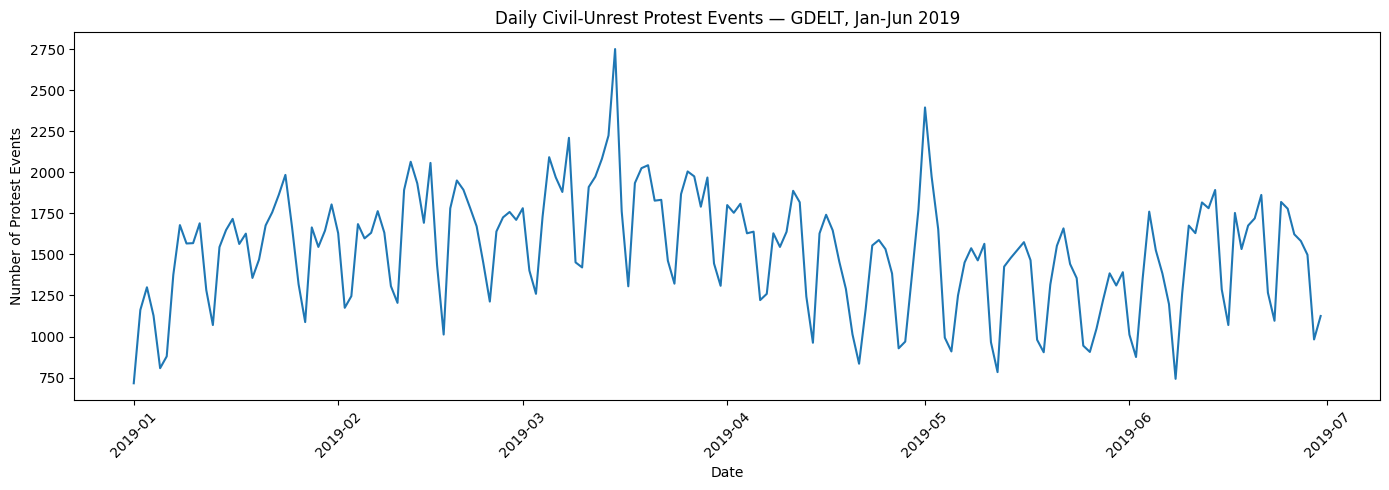

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

GDELT_PATH = "/kaggle/working/gdelt/gdelt_protests_2019_Jan_Jun_raw.csv"

gdelt = pd.read_csv(GDELT_PATH, low_memory=False)

print("Columns:", gdelt.columns.tolist()[:10])

# The raw GDELT file has numeric column names.
# Use column 1 for the actual event date.
date_col = "1" if "1" in gdelt.columns else 1

gdelt["EventDate"] = pd.to_datetime(
    gdelt[date_col].astype(str),
    format="%Y%m%d",
    errors="coerce"
)

# Keep valid dates from Jan-Jun 2019
gdelt = gdelt.dropna(subset=["EventDate"])

gdelt = gdelt[
    (gdelt["EventDate"] >= "2019-01-01") &
    (gdelt["EventDate"] <= "2019-06-30")
]

# Daily protest-event counts
daily_events = (
    gdelt.groupby("EventDate")
    .size()
    .reset_index(name="protest_count")
    .sort_values("EventDate")
)

print("\nDaily time-series shape:", daily_events.shape)
print("Date range:",
      daily_events["EventDate"].min(),
      "to",
      daily_events["EventDate"].max())

print("Total protest events:", daily_events["protest_count"].sum())

display(daily_events.head(10))

# Plot
plt.figure(figsize=(14, 5))
plt.plot(
    daily_events["EventDate"],
    daily_events["protest_count"]
)

plt.xlabel("Date")
plt.ylabel("Number of Protest Events")
plt.title("Daily Civil-Unrest Protest Events — GDELT, Jan-Jun 2019")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [43]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Make sure dates are sorted
daily_events = daily_events.sort_values("EventDate").reset_index(drop=True)

# -----------------------------
# 1. Normalize protest counts
# -----------------------------
scaler = MinMaxScaler()

daily_events["scaled_count"] = scaler.fit_transform(
    daily_events[["protest_count"]]
)

# -----------------------------
# 2. Create prediction target
# -----------------------------
# Target = 1 if protest activity in the NEXT 7 days
# is higher than the current 7-day average

window = 7

values = daily_events["scaled_count"].values
raw_counts = daily_events["protest_count"].values

X = []
y = []

for i in range(window, len(values) - window):

    # Previous 7 days = input sequence
    sequence = values[i-window:i]

    # Current 7-day average
    current_avg = raw_counts[i-window:i].mean()

    # Next 7-day average
    future_avg = raw_counts[i:i+window].mean()

    # 1 = increasing activity / early warning
    # 0 = not increasing
    target = 1 if future_avg > current_avg else 0

    X.append(sequence)
    y.append(target)

X = np.array(X)
y = np.array(y)

# GRU expects:
# samples × timesteps × features
X = X.reshape(X.shape[0], X.shape[1], 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(pd.Series(y).value_counts())

print("\nClass percentages:")
print(
    pd.Series(y)
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

X shape: (167, 7, 1)
y shape: (167,)

Class distribution:
1    85
0    82
Name: count, dtype: int64

Class percentages:
1    50.9
0    49.1
Name: proportion, dtype: float64


In [44]:
from sklearn.model_selection import train_test_split

# Chronological split: first 80% for training, last 20% for testing
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts())

X_train: (133, 7, 1)
X_test : (34, 7, 1)
y_train: (133,)
y_test : (34,)

Training class distribution:
0    69
1    64
Name: count, dtype: int64

Testing class distribution:
1    21
0    13
Name: count, dtype: int64


In [45]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout

# Build GRU model
gru_model = Sequential([
    GRU(32, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

gru_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

# Train
history = gru_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    verbose=1
)

I0000 00:00:1795535038.750695      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,905 (15.25 KB)

 Trainable params: 3,905 (15.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.4623 - loss: 0.7063 - val_accuracy: 0.5556 - val_loss: 0.6941
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4623 - loss: 0.6998 - val_accuracy: 0.5556 - val_loss: 0.6946
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5000 - loss: 0.6942 - val_accuracy: 0.5556 - val_loss: 0.6954
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5189 - loss: 0.6916 - val_accuracy: 0.4074 - val_loss: 0.6958
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5660 - loss: 0.6917 - val_accuracy: 0.3333 - val_loss: 0.6964
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5472 - loss: 0.6918 - val_accuracy: 0.4444 - val_loss: 0.6968
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5660 - loss: 0.6915 - val_accuracy: 0.4444 - val_loss: 0.6971
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5566 - loss: 0.6889 - val_accuracy: 0.4444 - val_loss: 0.6974


In [47]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Sort chronologically
daily_events = daily_events.sort_values("EventDate").reset_index(drop=True)

raw_counts = daily_events["protest_count"].values

# Chronological split of the raw time series
split_day = int(len(raw_counts) * 0.8)

train_raw = raw_counts[:split_day]

# Fit scaler ONLY on training data
scaler = MinMaxScaler()
scaler.fit(train_raw.reshape(-1, 1))

scaled_counts = scaler.transform(
    raw_counts.reshape(-1, 1)
).flatten()

# Create sequences
window = 7

X = []
y = []

for i in range(window, len(scaled_counts) - window):
    X.append(scaled_counts[i-window:i])

    current_avg = raw_counts[i-window:i].mean()
    future_avg = raw_counts[i:i+window].mean()

    y.append(1 if future_avg > current_avg else 0)

X = np.array(X).reshape(-1, window, 1)
y = np.array(y)

# Chronological sample split
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

X_train: (133, 7, 1)
X_test : (34, 7, 1)
y_train: (133,)
y_test : (34,)

Train distribution:
0    69
1    64
Name: count, dtype: int64

Test distribution:
1    21
0    13
Name: count, dtype: int64


In [48]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Dropout

# Build GRU model
gru_model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    GRU(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

gru_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Training GRU...")

history = gru_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    verbose=1
)

Training GRU...
Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.4340 - loss: 0.7006 - val_accuracy: 0.5556 - val_loss: 0.6925
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5000 - loss: 0.6946 - val_accuracy: 0.5556 - val_loss: 0.6928
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5000 - loss: 0.6940 - val_accuracy: 0.5185 - val_loss: 0.6933
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4906 - loss: 0.6951 - val_accuracy: 0.4074 - val_loss: 0.6940
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5755 - loss: 0.6882 - val_accuracy: 0.4444 - val_loss: 0.6947
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4906 - loss: 0.6908 - val_accuracy: 0.4444 - val_loss: 0.6952
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5755 - loss: 0.6900 - val_accuracy: 0.4444 - val_loss: 0.6958
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5377 - loss: 0.6896 - val_accuracy: 0.4444 - v

In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predict probabilities
y_prob = gru_model.predict(X_test).ravel()

# Convert probabilities to binary predictions
y_pred = (y_prob >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("GRU Test Results")
print("----------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nPrediction probabilities:")
print(np.round(y_prob, 3))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
GRU Test Results
----------------
Accuracy : 0.3824
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000

Confusion Matrix:
[[13  0]
 [21  0]]

Prediction probabilities:
[0.455 0.454 0.45  0.446 0.445 0.447 0.453 0.458 0.46  0.458 0.456 0.454
 0.453 0.456 0.458 0.454 0.449 0.446 0.446 0.451 0.455 0.454 0.45  0.444
 0.439 0.434 0.432 0.438 0.442 0.441 0.441 0.439 0.436 0.435]


In [50]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Use a 14-day historical window
window = 14

raw_counts = daily_events["protest_count"].values

# Fit scaler only on the first 80% of the raw timeline
split_day = int(len(raw_counts) * 0.8)

scaler = MinMaxScaler()
scaler.fit(raw_counts[:split_day].reshape(-1, 1))

scaled_counts = scaler.transform(
    raw_counts.reshape(-1, 1)
).flatten()

# Create sequences
X = []
y = []

for i in range(window, len(scaled_counts) - window):
    past = scaled_counts[i-window:i]

    current_avg = raw_counts[i-window:i].mean()
    future_avg = raw_counts[i:i+window].mean()

    target = 1 if future_avg > current_avg else 0

    X.append(past)
    y.append(target)

X = np.array(X).reshape(-1, window, 1)
y = np.array(y)

# Chronological split
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

X_train: (122, 14, 1)
X_test : (31, 14, 1)
y_train: (122,)
y_test : (31,)

Train distribution:
0    67
1    55
Name: count, dtype: int64

Test distribution:
1    19
0    12
Name: count, dtype: int64


In [51]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Dropout

gru_model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    GRU(16),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

gru_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

history = gru_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    verbose=1
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 16)             │           912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.4742 - loss: 0.6939 - val_accuracy: 0.6800 - val_loss: 0.6912
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4639 - loss: 0.6925 - val_accuracy: 0.6400 - val_loss: 0.6903
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5567 - loss: 0.6909 - val_accuracy: 0.6400 - val_loss: 0.6888
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5052 - loss: 0.6918 - val_accuracy: 0.6400 - val_loss: 0.6868
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5258 - loss: 0.6934 - val_accuracy: 0.6400 - val_loss: 0.6848
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5258 - loss: 0.6906 - val_accuracy: 0.6400 - val_loss: 0.6837
Epoch 7/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5361 - loss: 0.6910 - val_accuracy: 0.6400 - val_loss: 0.6824
Epoch 8/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5258 - loss: 0.6903 - val_accuracy: 0.6400 - val_loss: 0.6811


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predict on unseen test data
y_prob = gru_model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("GRU Test Results")
print("----------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nPrediction probabilities:")
print(np.round(y_prob, 3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
GRU Test Results
----------------
Accuracy : 0.3871
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000

Confusion Matrix:
[[12  0]
 [19  0]]

Prediction probabilities:
[0.427 0.425 0.424 0.427 0.43  0.431 0.429 0.426 0.425 0.425 0.428 0.431
 0.433 0.433 0.432 0.431 0.43  0.431 0.433 0.432 0.429 0.426 0.426 0.427
 0.431 0.431 0.429 0.426 0.422 0.42  0.416]


In [53]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Simple trend-based baseline
baseline_pred = []

for i in range(window, len(raw_counts) - window):
    recent = raw_counts[i-window:i]

    # Compare second half vs first half of recent history
    first_half = recent[:window//2].mean()
    second_half = recent[window//2:].mean()

    prediction = 1 if second_half > first_half else 0
    baseline_pred.append(prediction)

baseline_pred = np.array(baseline_pred)

# Use same test portion as GRU
baseline_test_pred = baseline_pred[split:]

print("Baseline Test Results")
print("---------------------")
print(f"Accuracy : {accuracy_score(y_test, baseline_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, baseline_test_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, baseline_test_pred, zero_division=0):.4f}")
print(f"F1 Score : {f1_score(y_test, baseline_test_pred, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_test_pred))

Baseline Test Results
---------------------
Accuracy : 0.5484
Precision: 0.6316
Recall   : 0.6316
F1 Score : 0.6316

Confusion Matrix:
[[ 5  7]
 [ 7 12]]


In [55]:
import numpy as np
import pandas as pd

df_rf = daily_events.copy()
df_rf = df_rf.sort_values("EventDate").reset_index(drop=True)

# Lag features
df_rf["lag_1"] = df_rf["protest_count"].shift(1)
df_rf["lag_3"] = df_rf["protest_count"].shift(3)
df_rf["lag_7"] = df_rf["protest_count"].shift(7)
df_rf["lag_14"] = df_rf["protest_count"].shift(14)

# Rolling statistics
df_rf["rolling_mean_3"] = df_rf["protest_count"].shift(1).rolling(3).mean()
df_rf["rolling_mean_7"] = df_rf["protest_count"].shift(1).rolling(7).mean()
df_rf["rolling_mean_14"] = df_rf["protest_count"].shift(1).rolling(14).mean()

df_rf["rolling_std_7"] = df_rf["protest_count"].shift(1).rolling(7).std()

# Recent trend
df_rf["trend_7"] = (
    df_rf["rolling_mean_7"] - df_rf["rolling_mean_14"]
)

# Target:
# 1 = next 14-day average is higher than previous 14-day average
# 0 = otherwise
df_rf["future_mean_14"] = (
    df_rf["protest_count"].shift(-1).rolling(14).mean()
)

df_rf["past_mean_14"] = (
    df_rf["protest_count"].shift(1).rolling(14).mean()
)

df_rf["target"] = (
    df_rf["future_mean_14"] > df_rf["past_mean_14"]
).astype(int)

# Remove rows with insufficient history/future information
df_rf = df_rf.dropna().reset_index(drop=True)

print("Random Forest dataset shape:", df_rf.shape)

print("\nClass distribution:")
print(df_rf["target"].value_counts())

print("\nClass percentages:")
print(
    df_rf["target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nFeatures:")
print([
    "lag_1",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_3",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "trend_7"
])

Random Forest dataset shape: (166, 15)

Class distribution:
target
0    85
1    81
Name: count, dtype: int64

Class percentages:
target
0    51.2
1    48.8
Name: proportion, dtype: float64

Features:
['lag_1', 'lag_3', 'lag_7', 'lag_14', 'rolling_mean_3', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'trend_7']


In [58]:
from sklearn.model_selection import train_test_split

FEATURES = [
    "lag_1",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_3",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "trend_7"
]

X_rf = df_rf[FEATURES]
y_rf = df_rf["target"]

# Chronological 80/20 split
split_rf = int(len(df_rf) * 0.8)

X_rf_train = X_rf.iloc[:split_rf]
X_rf_test = X_rf.iloc[split_rf:]

y_rf_train = y_rf.iloc[:split_rf]
y_rf_test = y_rf.iloc[split_rf:]

print("X_train:", X_rf_train.shape)
print("X_test :", X_rf_test.shape)
print("y_train:", y_rf_train.shape)
print("y_test :", y_rf_test.shape)

print("\nTraining distribution:")
print(y_rf_train.value_counts())

print("\nTesting distribution:")
print(y_rf_test.value_counts())

X_train: (132, 9)
X_test : (34, 9)
y_train: (132,)
y_test : (34,)

Training distribution:
target
0    70
1    62
Name: count, dtype: int64

Testing distribution:
target
1    19
0    15
Name: count, dtype: int64


In [59]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_rf_train, y_rf_train)

print("Random Forest training completed.")
print("Number of trees:", rf_model.n_estimators)
print("Maximum depth:", rf_model.max_depth)

Random Forest training completed.
Number of trees: 200
Maximum depth: 5


In [60]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predictions
y_rf_pred = rf_model.predict(X_rf_test)
y_rf_prob = rf_model.predict_proba(X_rf_test)[:, 1]

# Metrics
rf_accuracy = accuracy_score(y_rf_test, y_rf_pred)
rf_precision = precision_score(y_rf_test, y_rf_pred, zero_division=0)
rf_recall = recall_score(y_rf_test, y_rf_pred, zero_division=0)
rf_f1 = f1_score(y_rf_test, y_rf_pred, zero_division=0)

print("Random Forest Test Results")
print("--------------------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_rf_test, y_rf_pred))

print("\nPrediction probabilities:")
print(np.round(y_rf_prob, 3))

Random Forest Test Results
--------------------------
Accuracy : 0.6765
Precision: 0.7000
Recall   : 0.7368
F1 Score : 0.7179

Confusion Matrix:
[[ 9  6]
 [ 5 14]]

Prediction probabilities:
[0.215 0.271 0.26  0.249 0.291 0.302 0.266 0.27  0.396 0.659 0.726 0.828
 0.651 0.512 0.661 0.653 0.677 0.802 0.804 0.91  0.841 0.835 0.749 0.763
 0.853 0.818 0.796 0.231 0.296 0.311 0.519 0.688 0.478 0.238]


Random Forest Feature Importance
--------------------------------
        Feature  Importance
        trend_7    0.424691
         lag_14    0.114474
  rolling_std_7    0.104191
 rolling_mean_7    0.068088
          lag_1    0.067813
 rolling_mean_3    0.062238
rolling_mean_14    0.058866
          lag_7    0.052828
          lag_3    0.046810


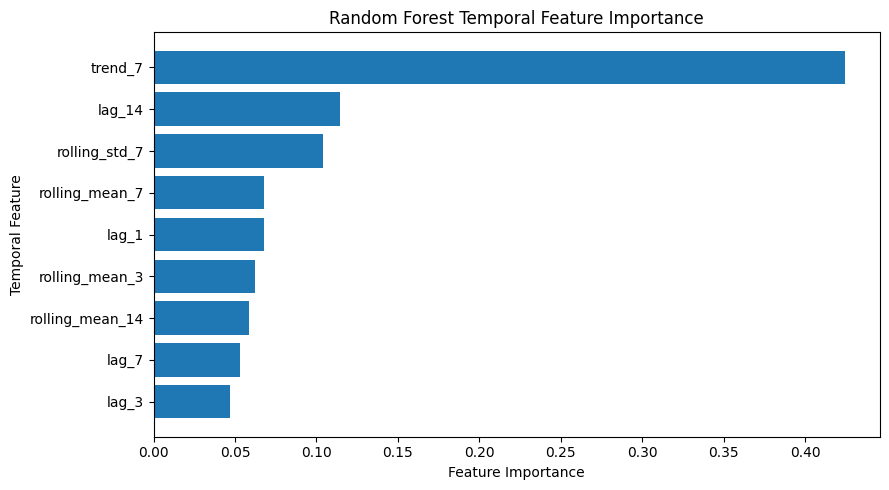

In [61]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Random Forest Feature Importance")
print("--------------------------------")
print(importance_df.to_string(index=False))

# Plot
plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Temporal Feature")
plt.title("Random Forest Temporal Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [62]:
def explain_temporal_prediction(model, feature_row):
    """
    Generate an explainable prediction from the Random Forest.
    """

    # Prediction probability
    probability = model.predict_proba(feature_row)[0, 1]

    # Prediction
    prediction = int(probability >= 0.5)

    # Risk level
    if probability >= 0.75:
        risk = "HIGH"
    elif probability >= 0.50:
        risk = "MEDIUM"
    else:
        risk = "LOW"

    # Feature contributions using feature importance
    contributions = pd.DataFrame({
        "Feature": FEATURES,
        "Importance": model.feature_importances_,
        "Value": feature_row.iloc[0].values
    })

    contributions["Impact"] = (
        contributions["Importance"] *
        contributions["Value"]
    )

    contributions = contributions.sort_values(
        "Impact",
        ascending=False
    )

    return {
        "prediction": prediction,
        "probability_increase": probability,
        "risk_level": risk,
        "top_factors": contributions.head(5)
    }


# Use the most recent available observation
latest_features = X_rf.iloc[[-1]]

explanation = explain_temporal_prediction(
    rf_model,
    latest_features
)

print("TEMPORAL EARLY-WARNING RESULT")
print("-----------------------------")

print(
    "Prediction:",
    "INCREASE" if explanation["prediction"] == 1
    else "NO INCREASE"
)

print(
    f"Probability of increased activity: "
    f"{explanation['probability_increase']:.2%}"
)

print("Risk Level:", explanation["risk_level"])

print("\nTop Factors:")
print(
    explanation["top_factors"].to_string(index=False)
)

TEMPORAL EARLY-WARNING RESULT
-----------------------------
Prediction: NO INCREASE
Probability of increased activity: 23.76%
Risk Level: LOW

Top Factors:
        Feature  Importance       Value     Impact
         lag_14    0.114474 1287.000000 147.327559
 rolling_mean_7    0.068088 1523.571429 103.737567
          lag_1    0.067813 1498.000000 101.584402
 rolling_mean_3    0.062238 1567.666667  97.568003
rolling_mean_14    0.058866 1540.500000  90.683475


Permutation Feature Importance
------------------------------
        Feature  Importance      Std
        trend_7    0.118118 0.081923
         lag_14    0.038300 0.027283
rolling_mean_14    0.033778 0.015503
  rolling_std_7    0.000203 0.017125
          lag_7    0.000000 0.000000
          lag_3   -0.007557 0.009256
          lag_1   -0.013225 0.008658
 rolling_mean_3   -0.013225 0.008658
 rolling_mean_7   -0.026958 0.023844


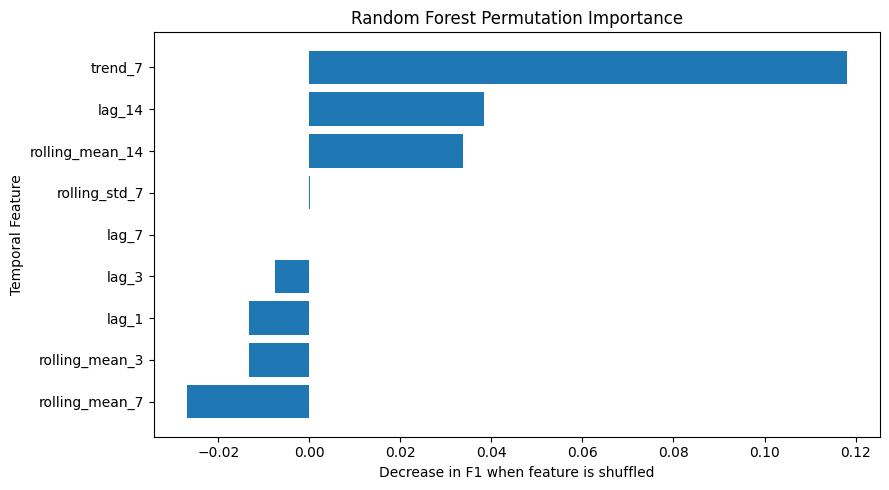

In [63]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on unseen test data
perm_result = permutation_importance(
    rf_model,
    X_rf_test,
    y_rf_test,
    n_repeats=10,
    random_state=42,
    scoring="f1"
)

permutation_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("Importance", ascending=False)

print("Permutation Feature Importance")
print("------------------------------")
print(permutation_df.to_string(index=False))

# Plot
plt.figure(figsize=(9, 5))

plt.barh(
    permutation_df["Feature"],
    permutation_df["Importance"]
)

plt.xlabel("Decrease in F1 when feature is shuffled")
plt.ylabel("Temporal Feature")
plt.title("Random Forest Permutation Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [64]:
# ============================================================
# LOAD XLM-R EVENT DETECTION MODEL
# ============================================================

import os
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_PATH = "/kaggle/working/xlm_roberta_event_detector"

print("Checking model path...")

if not os.path.exists(MODEL_PATH):
    print("ERROR: Model folder does not exist.")
    print("Contents of /kaggle/working/:")
    print(os.listdir("/kaggle/working/"))
else:
    print("Model folder found.")

    tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

    event_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_PATH
    )

    event_model.eval()

    print("\nXLM-R model loaded successfully.")
    print("Model:", type(event_model).__name__)
    print("Tokenizer loaded:", tokenizer is not None)

Checking model path...
Model folder found.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


XLM-R model loaded successfully.
Model: XLMRobertaForSequenceClassification
Tokenizer loaded: True


In [65]:
# ============================================================
# COMPLETE END-TO-END TEST — ALL 6 COMPONENTS
# ============================================================

import torch
import pandas as pd
import numpy as np

from sklearn.inspection import permutation_importance


# ============================================================
# CHECK REQUIRED COMPONENTS
# ============================================================

required = {
    "event_model": event_model,
    "tokenizer": tokenizer,
    "rf_model": rf_model,
    "daily_events": daily_events,
    "extract_event_information": extract_event_information,
    "detect_event_context": detect_event_context,
    "FEATURES": FEATURES
}

print("=" * 70)
print("CHECKING COMPONENTS")
print("=" * 70)

for name in required:
    print(f"{name:35} OK")

print("\nAll required components are available.")


# ============================================================
# TEST INPUT
# ============================================================

test_text = """
Thousands of students organized a protest in Delhi yesterday
against the new education policy. The demonstration is expected
to continue tomorrow.
"""

print("\n" + "=" * 70)
print("INPUT")
print("=" * 70)

print(test_text)


# ============================================================
# 1. EVENT DETECTION — XLM-RoBERTa
# ============================================================

print("\n" + "=" * 70)
print("1. EVENT DETECTION")
print("=" * 70)

inputs = tokenizer(
    test_text,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=256
)

with torch.no_grad():
    outputs = event_model(**inputs)

probs = torch.softmax(outputs.logits, dim=-1)

event_probability = probs[0, 1].item()

event_prediction = int(event_probability >= 0.5)

print(f"Event probability : {event_probability:.4f}")
print(f"Event detected    : {'YES' if event_prediction else 'NO'}")


# ============================================================
# 2. STRUCTURED INFORMATION EXTRACTION
# ============================================================

print("\n" + "=" * 70)
print("2. STRUCTURED INFORMATION EXTRACTION")
print("=" * 70)

structured_event = extract_event_information(test_text)

print("Event Type :", structured_event.get("event_type"))
print("Trigger    :", structured_event.get("trigger"))
print("Actor      :", structured_event.get("actor"))
print("Location   :", structured_event.get("location"))
print("Time       :", structured_event.get("time"))
print("Target     :", structured_event.get("target"))


# ============================================================
# 3. CONTEXT-AWARE EVENT ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("3. CONTEXT-AWARE EVENT ANALYSIS")
print("=" * 70)

context = detect_event_context(test_text)

print("Event Context :", context)


# ============================================================
# 4. TEMPORAL EVENT MODELING
# ============================================================

print("\n" + "=" * 70)
print("4. TEMPORAL EVENT MODELING")
print("=" * 70)

latest_14 = daily_events.tail(14)

recent_mean = latest_14["protest_count"].mean()
latest_count = latest_14["protest_count"].iloc[-1]

print("Latest 14-day average :", round(recent_mean, 2))
print("Latest protest count  :", int(latest_count))


# ============================================================
# CREATE TEMPORAL FEATURES
# ============================================================

temp_df = daily_events.copy()

temp_df["lag_1"] = temp_df["protest_count"].shift(1)
temp_df["lag_3"] = temp_df["protest_count"].shift(3)
temp_df["lag_7"] = temp_df["protest_count"].shift(7)
temp_df["lag_14"] = temp_df["protest_count"].shift(14)

temp_df["rolling_mean_3"] = (
    temp_df["protest_count"]
    .shift(1)
    .rolling(3)
    .mean()
)

temp_df["rolling_mean_7"] = (
    temp_df["protest_count"]
    .shift(1)
    .rolling(7)
    .mean()
)

temp_df["rolling_mean_14"] = (
    temp_df["protest_count"]
    .shift(1)
    .rolling(14)
    .mean()
)

temp_df["rolling_std_7"] = (
    temp_df["protest_count"]
    .shift(1)
    .rolling(7)
    .std()
)

temp_df["trend_7"] = (
    temp_df["rolling_mean_7"]
    - temp_df["rolling_mean_14"]
)

temp_df = temp_df.dropna().reset_index(drop=True)


# ============================================================
# 5. PREDICTIVE EARLY-WARNING — RANDOM FOREST
# ============================================================

print("\n" + "=" * 70)
print("5. PREDICTIVE EARLY-WARNING")
print("=" * 70)

latest_features = temp_df[FEATURES].tail(1)

prediction = rf_model.predict(latest_features)[0]

probability = rf_model.predict_proba(
    latest_features
)[0, 1]

if probability >= 0.75:
    risk = "HIGH"
elif probability >= 0.50:
    risk = "MEDIUM"
else:
    risk = "LOW"

print("Predicted increase :", "YES" if prediction == 1 else "NO")
print(f"Probability        : {probability:.2%}")
print("Risk level         :", risk)


# ============================================================
# 6. EXPLAINABLE INSIGHTS
# ============================================================

print("\n" + "=" * 70)
print("6. EXPLAINABLE INSIGHTS")
print("=" * 70)

perm = permutation_importance(
    rf_model,
    X_rf_test,
    y_rf_test,
    n_repeats=10,
    random_state=42,
    scoring="f1"
)

importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

print("\nTop factors influencing the model:")

print(
    importance_df.head(5).to_string(index=False)
)


# ============================================================
# FINAL INTEGRATED RESULT
# ============================================================

print("\n" + "=" * 70)
print("FINAL INTEGRATED RESULT")
print("=" * 70)

print(f"""
EVENT DETECTION
---------------
Detected        : {'YES' if event_prediction else 'NO'}
Probability     : {event_probability:.2%}

STRUCTURED EVENT
----------------
Type            : {structured_event.get("event_type")}
Trigger         : {structured_event.get("trigger")}
Actor           : {structured_event.get("actor")}
Location        : {structured_event.get("location")}
Time            : {structured_event.get("time")}
Target          : {structured_event.get("target")}

CONTEXT
-------
Status          : {context}

TEMPORAL MODEL
--------------
Future increase : {'YES' if prediction == 1 else 'NO'}
Probability     : {probability:.2%}
Risk level      : {risk}
""")

print("=" * 70)
print("ALL 6 COMPONENTS TESTED SUCCESSFULLY")
print("=" * 70)

CHECKING COMPONENTS
event_model                         OK
tokenizer                           OK
rf_model                            OK
daily_events                        OK
extract_event_information           OK
detect_event_context                OK
FEATURES                            OK

All required components are available.

INPUT

Thousands of students organized a protest in Delhi yesterday
against the new education policy. The demonstration is expected
to continue tomorrow.


1. EVENT DETECTION
Event probability : 0.9992
Event detected    : YES

2. STRUCTURED INFORMATION EXTRACTION
Event Type : protest
Trigger    : protest
Actor      : Thousands
Location   : Delhi
Time       : yesterday
Target     : the new education policy

3. CONTEXT-AWARE EVENT ANALYSIS
Event Context : PLANNED

4. TEMPORAL EVENT MODELING
Latest 14-day average : 1522.64
Latest protest count  : 1125

5. PREDICTIVE EARLY-WARNING
Predicted increase : NO
Probability        : 17.90%
Risk level         : LOW

6. E

In [66]:
# ============================================================
# EVENT-CHAIN AGGREGATION
# Structured Events -> Region + Time Window -> Event Chains
# ============================================================

import pandas as pd
import numpy as np
import re

# ------------------------------------------------------------
# 1. SAMPLE SOCIAL-MEDIA TEXT DATA
# ------------------------------------------------------------

texts = [
    "Students organized a protest in Delhi yesterday against the new education policy.",
    "Workers went on strike in Mumbai yesterday demanding higher wages.",
    "Police clashed with protesters in Delhi yesterday.",
    "Thousands of people joined a demonstration in Delhi.",
    "Students marched in Delhi against the education policy.",
    "Workers protested in Mumbai over salary issues.",
    "Police clashed with protesters in Mumbai.",
    "A large rally was held in Delhi yesterday.",
    "Students protested in Delhi demanding changes.",
    "Workers went on strike in Mumbai yesterday."
]

dates = pd.date_range(
    start="2019-01-01",
    periods=len(texts),
    freq="D"
)

# ------------------------------------------------------------
# 2. EXTRACT STRUCTURED EVENTS
# ------------------------------------------------------------

events = []

for text, date in zip(texts, dates):

    result = extract_event_information(text)

    events.append({
        "date": date,
        "text": text,
        "event_type": result.get("event_type"),
        "trigger": result.get("trigger"),
        "actor": result.get("actor"),
        "location": result.get("location"),
        "target": result.get("target")
    })

events_df = pd.DataFrame(events)

print("=" * 70)
print("STRUCTURED EVENTS")
print("=" * 70)

print(
    events_df[
        [
            "date",
            "event_type",
            "actor",
            "location",
            "target"
        ]
    ].to_string(index=False)
)


# ============================================================
# 3. CLEAN LOCATION
# ============================================================

events_df["region"] = events_df["location"].fillna("Unknown")

events_df["date"] = pd.to_datetime(events_df["date"])


# ============================================================
# 4. CREATE EVENT-CHAIN FEATURES
# ============================================================

# Count each event type by date + region

event_chain = (
    events_df
    .pivot_table(
        index=["date", "region"],
        columns="event_type",
        values="text",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

# Make sure all expected event columns exist

for col in ["protest", "strike", "clash", "riot", "unrest"]:
    if col not in event_chain.columns:
        event_chain[col] = 0


# ============================================================
# 5. TOTAL EVENTS
# ============================================================

event_chain["total_events"] = (
    event_chain["protest"]
    + event_chain["strike"]
    + event_chain["clash"]
    + event_chain["riot"]
    + event_chain["unrest"]
)


# ============================================================
# 6. SORT CHRONOLOGICALLY
# ============================================================

event_chain = event_chain.sort_values(
    ["region", "date"]
).reset_index(drop=True)


# ============================================================
# 7. TEMPORAL EVENT-CHAIN FEATURES
# ============================================================

event_chain["lag_1"] = (
    event_chain
    .groupby("region")["total_events"]
    .shift(1)
)

event_chain["lag_3"] = (
    event_chain
    .groupby("region")["total_events"]
    .shift(3)
)

event_chain["rolling_mean_3"] = (
    event_chain
    .groupby("region")["total_events"]
    .shift(1)
    .rolling(3)
    .mean()
    .reset_index(level=0, drop=True)
)

event_chain["rolling_mean_7"] = (
    event_chain
    .groupby("region")["total_events"]
    .shift(1)
    .rolling(7)
    .mean()
    .reset_index(level=0, drop=True)
)


# ============================================================
# 8. EVENT-CHAIN TREND
# ============================================================

event_chain["trend"] = (
    event_chain["rolling_mean_3"]
    - event_chain["rolling_mean_7"]
)


# ============================================================
# 9. DISPLAY FINAL EVENT CHAIN
# ============================================================

print("\n" + "=" * 70)
print("REGION + TIME EVENT CHAINS")
print("=" * 70)

print(
    event_chain[
        [
            "date",
            "region",
            "protest",
            "strike",
            "clash",
            "riot",
            "unrest",
            "total_events",
            "lag_1",
            "lag_3",
            "rolling_mean_3",
            "rolling_mean_7",
            "trend"
        ]
    ].to_string(index=False)
)


# ============================================================
# 10. SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("EVENT-CHAIN SUMMARY")
print("=" * 70)

print("Total extracted events :", len(events_df))
print("Regions identified     :", events_df["region"].nunique())
print("Event types identified :", events_df["event_type"].nunique())

print("\nEvent type counts:")
print(events_df["event_type"].value_counts())

print("\nRegion counts:")
print(events_df["region"].value_counts())

print("\nEvent-chain dataset shape:", event_chain.shape)

print("\nEVENT-CHAIN AGGREGATION COMPLETE")

STRUCTURED EVENTS
      date event_type     actor location                   target
2019-01-01    protest  Students    Delhi the new education policy
2019-01-02     strike   Workers   Mumbai             higher wages
2019-01-03      clash    Police    Delhi                     None
2019-01-04    protest Thousands    Delhi                     None
2019-01-05    protest  Students    Delhi     the education policy
2019-01-06    protest   Workers   Mumbai            salary issues
2019-01-07      clash    Police   Mumbai                     None
2019-01-08    protest     rally    Delhi                     None
2019-01-09    protest  Students    Delhi                  changes
2019-01-10     strike   Workers   Mumbai                     None

REGION + TIME EVENT CHAINS
      date region  protest  strike  clash  riot  unrest  total_events  lag_1  lag_3  rolling_mean_3  rolling_mean_7  trend
2019-01-01  Delhi        1       0      0     0       0             1    NaN    NaN             NaN      

In [67]:
# ============================================================
# FIXED EVENT-CHAIN AGGREGATION
# Continuous daily timeline per region
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. MAKE SURE DATES ARE DATETIME
# ------------------------------------------------------------

events_df["date"] = pd.to_datetime(events_df["date"])

events_df["region"] = events_df["location"].fillna("Unknown")


# ============================================================
# 2. AGGREGATE EVENTS BY DATE + REGION
# ============================================================

daily_chain = (
    events_df
    .pivot_table(
        index=["date", "region"],
        columns="event_type",
        values="text",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

# Make sure every event type exists

for col in ["protest", "strike", "clash", "riot", "unrest"]:
    if col not in daily_chain.columns:
        daily_chain[col] = 0


# ============================================================
# 3. CREATE COMPLETE DATE RANGE
# ============================================================

min_date = events_df["date"].min()
max_date = events_df["date"].max()

all_dates = pd.date_range(
    start=min_date,
    end=max_date,
    freq="D"
)

regions = events_df["region"].unique()

complete_index = pd.MultiIndex.from_product(
    [all_dates, regions],
    names=["date", "region"]
)

daily_chain = (
    daily_chain
    .set_index(["date", "region"])
    .reindex(complete_index, fill_value=0)
    .reset_index()
)


# ============================================================
# 4. TOTAL EVENTS
# ============================================================

daily_chain["total_events"] = (
    daily_chain["protest"]
    + daily_chain["strike"]
    + daily_chain["clash"]
    + daily_chain["riot"]
    + daily_chain["unrest"]
)


# ============================================================
# 5. SORT
# ============================================================

daily_chain = daily_chain.sort_values(
    ["region", "date"]
).reset_index(drop=True)


# ============================================================
# 6. TEMPORAL FEATURES
# ============================================================

grouped = daily_chain.groupby("region")["total_events"]

daily_chain["lag_1"] = grouped.shift(1)
daily_chain["lag_3"] = grouped.shift(3)
daily_chain["lag_7"] = grouped.shift(7)

daily_chain["rolling_mean_3"] = (
    grouped
    .shift(1)
    .rolling(3)
    .mean()
    .reset_index(level=0, drop=True)
)

daily_chain["rolling_mean_7"] = (
    grouped
    .shift(1)
    .rolling(7)
    .mean()
    .reset_index(level=0, drop=True)
)

daily_chain["rolling_std_7"] = (
    grouped
    .shift(1)
    .rolling(7)
    .std()
    .reset_index(level=0, drop=True)
)

daily_chain["trend_3_7"] = (
    daily_chain["rolling_mean_3"]
    - daily_chain["rolling_mean_7"]
)


# ============================================================
# 7. SHOW RESULT
# ============================================================

print("=" * 70)
print("CONTINUOUS EVENT CHAIN")
print("=" * 70)

print(
    daily_chain.to_string(index=False)
)


# ============================================================
# 8. SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("EVENT-CHAIN SUMMARY")
print("=" * 70)

print("Date range       :", min_date.date(), "to", max_date.date())
print("Regions           :", list(regions))
print("Total rows        :", len(daily_chain))
print("Total events      :", int(daily_chain["total_events"].sum()))

print("\nEvents by region:")
print(
    daily_chain
    .groupby("region")["total_events"]
    .sum()
)

print("\nEvents by type:")

print(
    events_df["event_type"]
    .value_counts()
)

print("\nContinuous event-chain dataset created successfully.")

CONTINUOUS EVENT CHAIN
      date region  clash  protest  strike  riot  unrest  total_events  lag_1  lag_3  lag_7  rolling_mean_3  rolling_mean_7  rolling_std_7  trend_3_7
2019-01-01  Delhi      0        1       0     0       0             1    NaN    NaN    NaN             NaN             NaN            NaN        NaN
2019-01-02  Delhi      0        0       0     0       0             0    1.0    NaN    NaN             NaN             NaN            NaN        NaN
2019-01-03  Delhi      1        0       0     0       0             1    0.0    NaN    NaN             NaN             NaN            NaN        NaN
2019-01-04  Delhi      0        1       0     0       0             1    1.0    1.0    NaN        0.666667             NaN            NaN        NaN
2019-01-05  Delhi      0        1       0     0       0             1    1.0    0.0    NaN        0.666667             NaN            NaN        NaN
2019-01-06  Delhi      0        0       0     0       0             0    1.0    1.0

In [80]:
import os

XLM_PATH = "/kaggle/working/xlm_roberta_event_detector"

event_model.save_pretrained(XLM_PATH)
tokenizer.save_pretrained(XLM_PATH)

print("XLM-RoBERTa saved.")
print(os.listdir(XLM_PATH))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

XLM-RoBERTa saved.
['checkpoint-120', 'training_args.bin', 'checkpoint-77', 'model.safetensors', 'tokenizer_config.json', 'checkpoint-40', 'checkpoint-80', 'config.json', 'tokenizer.json']


In [81]:
GRU_PATH = "/kaggle/working/gru_14day_model.keras"

gru_model.save(GRU_PATH)

print("GRU saved.")
print(os.path.getsize(GRU_PATH) / (1024 * 1024), "MB")

GRU saved.
0.041939735412597656 MB


In [82]:
import joblib
import json

RF_PATH = "/kaggle/working/random_forest_temporal_model.joblib"

joblib.dump(rf_model, RF_PATH)

with open("/kaggle/working/rf_features.json", "w") as f:
    json.dump(FEATURES, f)

print("Random Forest saved.")
print(os.path.getsize(RF_PATH) / (1024 * 1024), "MB")

Random Forest saved.
0.44149112701416016 MB


In [83]:
import os

print("XLM-RoBERTa:",
      os.path.exists("/kaggle/working/xlm_roberta_event_detector"))

print("GRU:",
      os.path.exists("/kaggle/working/gru_14day_model.keras"))

print("Random Forest:",
      os.path.exists("/kaggle/working/random_forest_temporal_model.joblib"))

XLM-RoBERTa: True
GRU: True
Random Forest: True


In [85]:
import os
import shutil

# Remove the incomplete package
package_dir = "/kaggle/working/civil_unrest_models"

if os.path.exists(package_dir):
    shutil.rmtree(package_dir)

# Create clean package
os.makedirs(package_dir, exist_ok=True)

# Copy ONLY the final XLM-R model files, not checkpoints
xlm_src = "/kaggle/working/xlm_roberta_event_detector"
xlm_dst = f"{package_dir}/xlm_roberta_event_detector"

os.makedirs(xlm_dst, exist_ok=True)

files_to_copy = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json",
    "special_tokens_map.json",
    "sentencepiece.bpe.model"
]

for file in files_to_copy:
    src = os.path.join(xlm_src, file)
    if os.path.exists(src):
        shutil.copy2(src, xlm_dst)

# Copy GRU
shutil.copy(
    "/kaggle/working/gru_14day_model.keras",
    package_dir
)

# Copy Random Forest
shutil.copy(
    "/kaggle/working/random_forest_temporal_model.joblib",
    package_dir
)

# Copy RF feature list
shutil.copy(
    "/kaggle/working/rf_features.json",
    package_dir
)

# Create ZIP
zip_path = shutil.make_archive(
    "/kaggle/working/civil_unrest_models",
    "zip",
    package_dir
)

print("Package created successfully:")
print(zip_path)

print("\nContents:")
for root, dirs, files in os.walk(package_dir):
    for file in files:
        print(os.path.join(root, file))

Package created successfully:
/kaggle/working/civil_unrest_models.zip

Contents:
/kaggle/working/civil_unrest_models/rf_features.json
/kaggle/working/civil_unrest_models/gru_14day_model.keras
/kaggle/working/civil_unrest_models/random_forest_temporal_model.joblib
/kaggle/working/civil_unrest_models/xlm_roberta_event_detector/model.safetensors
/kaggle/working/civil_unrest_models/xlm_roberta_event_detector/tokenizer_config.json
/kaggle/working/civil_unrest_models/xlm_roberta_event_detector/config.json
/kaggle/working/civil_unrest_models/xlm_roberta_event_detector/tokenizer.json


In [86]:
from IPython.display import FileLink

FileLink("/kaggle/working/civil_unrest_models.zip")

/kaggle/working/civil_unrest_models.zip

In [87]:
import os

print(os.path.exists("/kaggle/working/civil_unrest_models.zip"))
print(os.path.getsize("/kaggle/working/civil_unrest_models.zip") / (1024*1024), "MB")

True
737.3917798995972 MB


In [88]:
from IPython.display import display, HTML

display(HTML("""
<a href="/kaggle/working/civil_unrest_models.zip" download>
Download civil_unrest_models.zip
</a>
"""))